# 04 – Định nghĩa "rời bỏ" (churn) và tạo bộ dữ liệu cho mô hình

**Đầu vào:** `fact_sales`, `fact_returns`, `dim_customer` (notebook 02).
**Đầu ra:** bảng `churn_dataset` trong PostgreSQL: mỗi dòng là một khách hàng tại một ngày chụp, gồm các đặc trưng và nhãn rời bỏ.

**Bán lẻ không có hợp đồng:** Khách không "hủy tài khoản", họ chỉ ngừng mua. Vì vậy ta **tự định nghĩa** rời bỏ theo thời gian:

> Tại một ngày cắt (cutoff), khách được gán **rời bỏ (1)** nếu *không mua lần nào trong H ngày tiếp theo*, ngược lại là **giữ chân (0)**.

> Quá khứ: dùng để tính đặc trưng ------|cutoff|--- H ngày tương lai: dùng để gán nhãn.

**Quy tắc quan trọng:** đặc trưng chỉ được dùng dữ liệu *đến ngày cutoff*, nếu không mô hình sẽ "nhìn trộm" tương lai và kết quả cao giả tạo.
Chỉ xét khách **đã mua trong 365 ngày trước cutoff** (khách bỏ đi từ lâu không cần dự báo).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from getpass import getpass
from pathlib import Path
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
Path("figures").mkdir(exist_ok=True)

engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres", password=getpass("Mật khẩu PostgreSQL: "),
    host="localhost", port=5432, database="Churn_Data"))

Mật khẩu PostgreSQL:  ········


## 1. Đọc dữ liệu và gộp theo hóa đơn

In [2]:
tx = pd.read_sql("""
    SELECT customer_key, invoice_no, order_date, stock_code, quantity,
           CAST(revenue AS DOUBLE PRECISION) AS revenue
    FROM fact_sales
    WHERE customer_key <> 0
""", engine)
tx["order_date"] = pd.to_datetime(tx["order_date"])

# Mỗi dòng = một hóa đơn của một khách (nhỏ gọn hơn nhiều so với từng dòng sản phẩm)
hd = tx.groupby(["customer_key", "invoice_no"]).agg(
    order_date=("order_date", "min"),
    revenue=("revenue", "sum"),
    n_sku=("stock_code", "nunique"),       # số sản phẩm khác nhau trong hóa đơn
    so_luong=("quantity", "sum"),
    so_dong=("stock_code", "size")).reset_index()

# Đơn hoàn/hủy và nhóm nước của khách (UK hay xuất khẩu)
hoan = pd.read_sql("SELECT customer_key, invoice_no, order_date AS return_date FROM fact_returns WHERE customer_key <> 0", engine)
hoan["return_date"] = pd.to_datetime(hoan["return_date"])

khach_uk = pd.read_sql("""
    SELECT customer_key, CASE WHEN country_group = 'UK' THEN 1 ELSE 0 END AS is_uk
    FROM dim_customer WHERE customer_key <> 0
""", engine).set_index("customer_key")["is_uk"]

NGAY_CUOI = hd["order_date"].max()
print(f"{len(hd):,} hóa đơn | {hd['customer_key'].nunique():,} khách | dữ liệu đến {NGAY_CUOI.date()}")

36,471 hóa đơn | 5,851 khách | dữ liệu đến 2011-12-09


## 2. Chọn H: khách thường vắng bao lâu giữa hai lần mua?
Nếu H quá nhỏ, nhiều khách chỉ có chu kỳ mua dài sẽ bị gắn nhầm là "rời bỏ". Nếu H quá lớn, cảnh báo đến muộn.
Ta xem khoảng cách (số ngày) giữa hai lần mua liên tiếp của cùng một khách.

Khoảng cách giữa hai lần mua liên tiếp (ngày):
50% (trung vị)    32.00
75%               71.00
80%               88.00
90%              148.00
95%              221.00


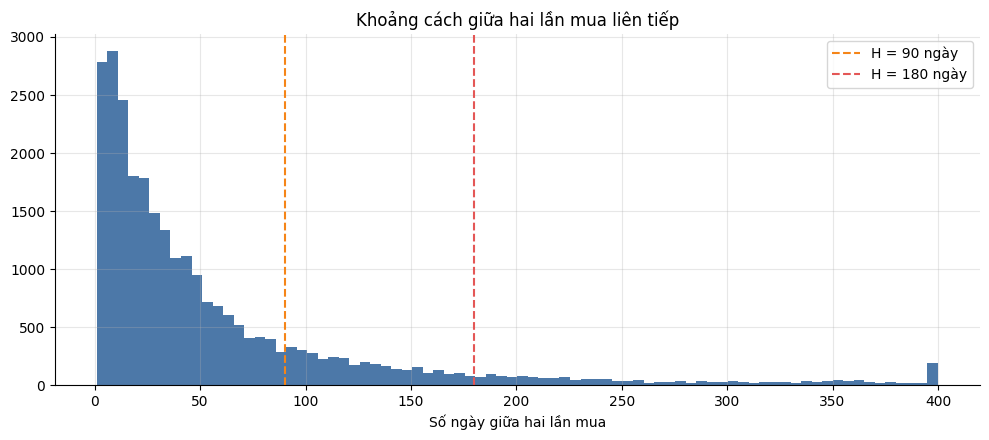

In [3]:
ngay_mua = hd[["customer_key", "order_date"]].drop_duplicates().sort_values(["customer_key", "order_date"])
khoang_cach = ngay_mua.groupby("customer_key")["order_date"].diff().dt.days.dropna()

phan_vi = khoang_cach.quantile([0.5, 0.75, 0.8, 0.9, 0.95]).round(0)
phan_vi.index = ["50% (trung vị)", "75%", "80%", "90%", "95%"]
print("Khoảng cách giữa hai lần mua liên tiếp (ngày):")
print(phan_vi.to_string())

fig, ax = plt.subplots()
ax.hist(khoang_cach.clip(upper=400), bins=80, color="#4C78A8")
ax.axvline(90, color="#F58518", ls="--", label="H = 90 ngày")
ax.axvline(180, color="#E45756", ls="--", label="H = 180 ngày")
ax.set_xlabel("Số ngày giữa hai lần mua"); ax.set_title("Khoảng cách giữa hai lần mua liên tiếp"); ax.legend()
plt.tight_layout(); plt.savefig("figures/04_khoang_cach_giua_2_lan_mua.png", dpi=150); plt.show()

**Lựa chọn:** H = 90 ngày tương ứng khoảng 80% các lần quay lại, tức khoảng 1/5 khách bị gắn "rời bỏ" thật ra chỉ có chu kỳ mua dài. H = 180 ngày an toàn hơn nhưng cảnh báo muộn.
Ta dùng **H = 90 ngày làm nhãn chính** (cảnh báo sớm để kịp chăm sóc) và vẫn lưu nhãn H = 180 ngày để so sánh tỷ lệ rời bỏ.

## 3. Tạo "ảnh chụp" khách hàng tại một ngày cutoff
Hàm `tao_snapshot` trả về một bảng, mỗi dòng là một khách đang hoạt động, gồm **đặc trưng** (tính từ quá khứ) và **nhãn** (nhìn vào tương lai).

| Nhóm đặc trưng | Ý nghĩa |
|---|---|
| recency, tenure | Bao lâu chưa mua; khách đã gắn bó bao lâu |
| frequency, monetary, aov | Số hóa đơn, tổng chi tiêu, giá trị trung bình mỗi hóa đơn |
| freq / mon 90, 180, 365 ngày | Mức mua gần đây |
| xu_huong_freq | Gần đây mua nhiều hơn hay ít hơn so với trước đó |
| avg_gap, rec_gap_ratio | Nhịp mua riêng của khách; tỷ lệ "đã vắng bao lâu so với nhịp thường lệ" |
| sku_per_invoice, qty_per_line | Thói quen giỏ hàng (mua sỉ hay lẻ) |
| so_don_hoan, ti_le_hoan | Mức hoàn/hủy |
| is_uk | Khách ở UK hay nước ngoài |

In [4]:
def tao_snapshot(ngay_cat):
    """Bảng đặc trưng và nhãn của các khách đang hoạt động tại ngày cutoff."""
    ngay_cat = pd.Timestamp(ngay_cat)
    qk = hd[hd["order_date"] <= ngay_cat]                  # chỉ dùng lịch sử đến ngày cutoff
    nhom = qk.groupby("customer_key")

    f = pd.DataFrame({
        "recency": (ngay_cat - nhom["order_date"].max()).dt.days,
        "tenure": (ngay_cat - nhom["order_date"].min()).dt.days,
        "frequency": nhom["invoice_no"].count(),
        "monetary": nhom["revenue"].sum(),
        "aov": nhom["revenue"].mean(),
        "sku_per_invoice": nhom["n_sku"].mean(),
        "qty_per_line": nhom["so_luong"].sum() / nhom["so_dong"].sum(),
    })

    # Mức mua trong 90, 180, 365 ngày gần nhất
    for w in (90, 180, 365):
        gan = qk[qk["order_date"] > ngay_cat - pd.Timedelta(days=w)].groupby("customer_key")
        f[f"freq_{w}d"] = gan["invoice_no"].count()
        f[f"mon_{w}d"] = gan["revenue"].sum()
    cot_cua_so = [c for c in f.columns if c.startswith(("freq_", "mon_"))]
    f[cot_cua_so] = f[cot_cua_so].fillna(0)                 # không mua trong cửa sổ => 0
    f["xu_huong_freq"] = f["freq_90d"] / (f["freq_180d"] - f["freq_90d"] + 1)     # < 1: đang mua chậm lại

    # Nhịp mua: số ngày trung bình giữa hai lần mua. Khách mới mua 1 lần thì chưa có nhịp => gán -1 và có cờ riêng
    nm = qk[["customer_key", "order_date"]].drop_duplicates().sort_values(["customer_key", "order_date"])
    nm["kc"] = nm.groupby("customer_key")["order_date"].diff().dt.days
    f["avg_gap"] = nm.groupby("customer_key")["kc"].mean()
    f["mua_mot_lan"] = f["avg_gap"].isna().astype(int)
    f["rec_gap_ratio"] = (f["recency"] / (f["avg_gap"] + 1)).where(f["avg_gap"].notna(), -1)
    f["avg_gap"] = f["avg_gap"].fillna(-1)

    # Hoàn/hủy đến ngày cutoff
    so_hoan = hoan[hoan["return_date"] <= ngay_cat].groupby("customer_key")["invoice_no"].nunique()
    f["so_don_hoan"] = so_hoan.reindex(f.index).fillna(0)
    f["ti_le_hoan"] = f["so_don_hoan"] / (f["frequency"] + f["so_don_hoan"])
    f["is_uk"] = khach_uk.reindex(f.index).fillna(0).astype(int)

    # Chỉ giữ khách đã mua trong 365 ngày gần nhất
    f = f[f["recency"] < 365].copy()

    # Nhãn: 1 = KHÔNG mua trong H ngày sau cutoff. Nếu cutoff + H vượt ngày cuối dữ liệu thì chưa biết nhãn (để trống)
    for h in (90, 180):
        if ngay_cat + pd.Timedelta(days=h) <= NGAY_CUOI:
            sau = hd[(hd["order_date"] > ngay_cat) & (hd["order_date"] <= ngay_cat + pd.Timedelta(days=h))]
            f[f"churn_{h}"] = (~f.index.isin(sau["customer_key"])).astype(float)
        else:
            f[f"churn_{h}"] = np.nan

    f["cutoff_date"] = ngay_cat
    return f.reset_index()

In [5]:
# Thử với một ngày cutoff
thu = tao_snapshot("2010-12-09")
print(thu.shape)
thu.head()

(4220, 24)


,customer_key,recency,tenure,frequency,monetary,aov,sku_per_invoice,qty_per_line,freq_90d,mon_90d,...,xu_huong_freq,avg_gap,mua_mot_lan,rec_gap_ratio,so_don_hoan,ti_le_hoan,is_uk,churn_90,churn_180,cutoff_date
0,12346,164,282,2,169.36,84.68,12.00,1.00,0.00,0.00,...,0.00,118.00,0,1.38,0.00,0.00,1,1.00,1.00,2010-12-09
1,12347,2,39,2,"1,323.32",661.66,35.50,11.66,2.00,"1,323.32",...,2.00,37.00,0,0.05,0.00,0.00,0,0.00,0.00,2010-12-09
2,12348,73,73,1,221.16,221.16,19.00,19.58,1.00,221.16,...,1.00,-1.00,1,-1.00,0.00,0.00,0,0.00,0.00,2010-12-09
3,12349,42,224,2,"2,221.14","1,110.57",50.00,9.91,1.00,"1,152.62",...,1.00,182.00,0,0.23,1.00,0.33,0,1.00,1.00,2010-12-09
4,12351,10,10,1,300.93,300.93,21.00,12.43,1.00,300.93,...,1.00,-1.00,1,-1.00,0.00,0.00,0,1.00,1.00,2010-12-09


## 4. Tạo bộ dữ liệu từ nhiều ngày cutoff
Mỗi quý lấy một ngày cutoff vào ngày 09. Ngày cutoff cuối phải thỏa **cutoff + 90 ngày ≤ ngày cuối dữ liệu** (09/09/2011), nếu không sẽ chưa biết nhãn.
Ngày cuối dữ liệu (09/12/2011) cũng được tạo ảnh chụp nhưng **chưa có nhãn**: đây là bộ khách sẽ được chấm điểm ở notebook 06.

In [6]:
CAC_MOC = ["2010-03-09", "2010-06-09", "2010-09-09", "2010-12-09", "2011-03-09", "2011-06-09", "2011-09-09"]

du_lieu = pd.concat([tao_snapshot(d) for d in CAC_MOC + [NGAY_CUOI]], ignore_index=True)
du_lieu["is_latest"] = (du_lieu["cutoff_date"] == NGAY_CUOI).astype(int)
du_lieu["cutoff_date"] = du_lieu["cutoff_date"].dt.date
print("Tổng:", du_lieu.shape)

Tổng: (29352, 25)


## 5. Kiểm tra: tỷ lệ rời bỏ theo từng ngày cutoff

In [7]:
bang_churn = du_lieu.groupby("cutoff_date").agg(
    so_khach=("customer_key", "count"),
    churn_90_pct=("churn_90", lambda s: s.mean() * 100),
    churn_180_pct=("churn_180", lambda s: s.mean() * 100))
bang_churn

,so_khach,churn_90_pct,churn_180_pct
cutoff_date,,,
2010-03-09,1853,39.94,27.63
2010-06-09,2772,51.66,28.86
2010-09-09,3348,42.41,36.56
2010-12-09,4220,68.96,53.51
2011-03-09,4271,63.26,51.77
2011-06-09,4323,64.26,43.00
2011-09-09,4305,49.29,NaN
2011-12-09,4260,NaN,NaN


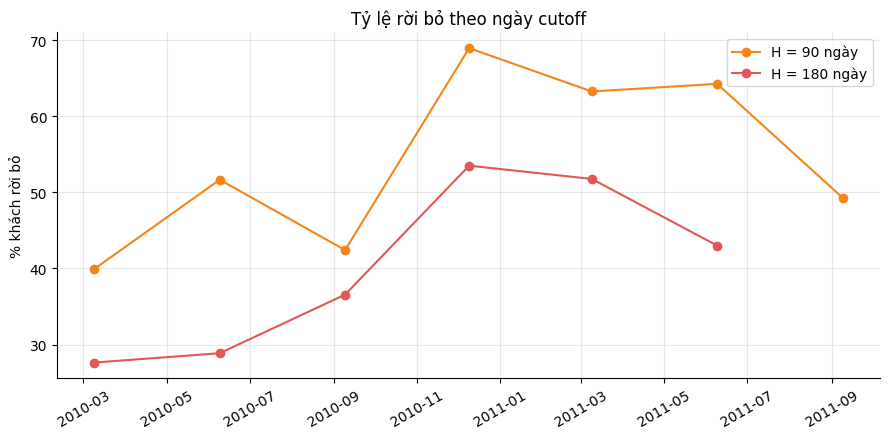

In [8]:
ax = bang_churn[["churn_90_pct", "churn_180_pct"]].plot(marker="o", figsize=(9, 4.5), color=["#F58518", "#E45756"])
ax.set_ylabel("% khách rời bỏ"); ax.set_xlabel(""); ax.set_title("Tỷ lệ rời bỏ theo ngày cutoff")
ax.legend(["H = 90 ngày", "H = 180 ngày"]); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig("figures/04_ti_le_churn_theo_cutoff.png", dpi=150); plt.show()

**Nhận xét:** tỷ lệ rời bỏ thay đổi theo mùa. Cutoff vào tháng 9 nhìn vào mùa cao điểm cuối năm nên tỷ lệ thấp; cutoff vào tháng 12 nhìn vào đầu năm là mùa thấp điểm nên tỷ lệ cao.

In [9]:
# Khách mới mua 1 lần có dễ rời bỏ hơn không?
du_lieu[du_lieu["churn_90"].notna()].groupby("mua_mot_lan").agg(
    so_dong=("churn_90", "size"), ti_le_roi_bo_pct=("churn_90", lambda s: s.mean() * 100))

,so_dong,ti_le_roi_bo_pct
mua_mot_lan,,
0,16466,46.91
1,8626,73.95


## 6. Ghi vào PostgreSQL

In [10]:
du_lieu.to_sql("churn_dataset", engine, if_exists="replace", index=False, chunksize=5000, method="multi")
n_db = int(pd.read_sql("SELECT COUNT(*) AS n FROM churn_dataset", engine)["n"][0])
print("Đã ghi churn_dataset:", n_db, "dòng | trong notebook:", len(du_lieu), "| khớp:", n_db == len(du_lieu))

Đã ghi churn_dataset: 29352 dòng | trong notebook: 29352 | khớp: True


## 7. Tổng kết
- **Định nghĩa rời bỏ:** khách không mua lần nào trong 90 ngày sau ngày cutoff (nhãn chính); 180 ngày dùng để so sánh.
- Bộ dữ liệu gồm 7 ngày cutoff có nhãn và 1 ảnh chụp mới nhất chưa có nhãn (dùng để chấm điểm).
- Mọi đặc trưng chỉ dùng dữ liệu đến ngày cutoff để tránh "nhìn trộm" tương lai.